# Simple neural network with Keras

In this demonstration, we build with Keras neural networks that recognize MNIST's handwritten digits:

1. a multinomial logistic regression, the network without a hidden layer, and how its output must match its loss;
2. a regularized multilayer perceptron;
3. monitoring the training with TensorBoard, early stopping and saving the best model;
4. a hyperparameter search with KerasTuner.

You don't need a GPU for this demonstration: each training is fast on CPU, and only the hyperparameter search, the last part, takes a few minutes. You can therefore switch runtime if the one you were given has a GPU (`Runtime > Change runtime type`).

In [1]:
!pip install -q keras-tuner
import keras
import keras_tuner
import matplotlib.pyplot as plt
import numpy as np
from keras import layers

# Same random draws on every run: reproducible results
keras.utils.set_random_seed(0)

## Data

This time, we load the dataset through Keras.

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

## Have a look at the data

Let's start with how the data is stored: the shape and type of the four arrays, the value of the first labels, the range of the pixels and the number of examples of each class.

In [3]:
print(f"Shape of X_train: {X_train.shape}, of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}, of y_test: {y_test.shape}")
print(f"Image type: {X_train.dtype}, from {X_train.min()} to {X_train.max()}")
print(f"Label type: {y_train.dtype}, first ones: {y_train[:10]}")
print(f"Examples per class: {np.bincount(y_train)}")

Shape of X_train: (60000, 28, 28), of X_test: (10000, 28, 28)
Shape of y_train: (60000,), of y_test: (10000,)
Image type: uint8, from 0 to 255
Label type: uint8, first ones: [5 0 4 1 9 2 1 3 1 4]
Examples per class: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


We have 60,000 training images and 10,000 test images, of 28 × 28 pixels: 8-bit unsigned integers (`uint8`), from 0 to 255. The labels are integers, from 0 to 9. Each class has from 5,421 to 6,742 examples: the classes are roughly balanced.

Here are the first ten images, with their label.

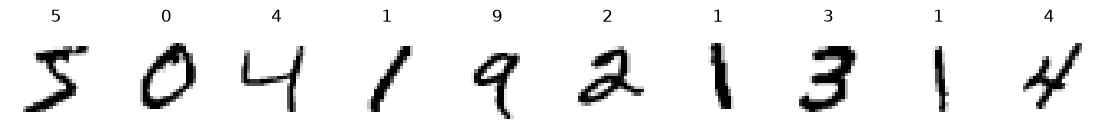

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
  ax.imshow(X_train[i], cmap="gray_r")
  ax.set_title(y_train[i])
  ax.axis("off")
plt.show()

## Data transformation

We need to transform this data:

1. Flatten the images: an array of shape `(_, 784)` rather than `(_, 28, 28)`, where `_` is the number of examples. Each image becomes a vector of 784 pixels, the input a `Dense` layer expects.
2. Bring the pixels into the $[0, 1]$ range rather than $[0, 255]$.
3. [One-hot](https://en.wikipedia.org/wiki/One-hot) encode the classes: the first of the two losses we will see, `categorical_crossentropy`, expects 10 values per example, all zero except for a 1 at the index of its class.

We keep `y_train` and `y_test`, and store the encoded classes in `Y_train` and `Y_test`.

In [5]:
nb_classes = 10
input_dim = 28 * 28

# "Flat" images: the network's input is a vector of input_dim pixels, in [0, 1].
# -1 lets NumPy compute the number of examples.
X_train = X_train.reshape(-1, input_dim) / 255
X_test = X_test.reshape(-1, input_dim) / 255

# The classes as one-hot vectors, for categorical_crossentropy
Y_train = keras.utils.to_categorical(y_train, num_classes=nb_classes)
Y_test = keras.utils.to_categorical(y_test, num_classes=nb_classes)
print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
print(f"Label {y_train[0]} one-hot encoded: {Y_train[0]}")

(60000, 784) (10000, 784) (60000, 10) (10000, 10)
Label 5 one-hot encoded: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Multinomial logistic regression

The first model has no hidden layer: a `keras.Input` of `input_dim` pixels, then a `layers.Dense` layer of `nb_classes` neurons, with the softmax activation. Each neuron computes a linear combination of the pixels, and the softmax turns them into 10 probabilities that sum to 1: this is a multinomial logistic regression.

In [6]:
model = keras.Sequential(
  [keras.Input(shape=(input_dim,)), layers.Dense(nb_classes, activation="softmax")]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

A `Dense` layer has one weight per input and per neuron, plus one bias per neuron: 784 × 10 + 10 = 7,850 parameters. `None` is the batch size, left free.

## Training

We compile the model with `compile`: the `"sgd"` optimizer (stochastic gradient descent, learning rate of 0.01), the `categorical_crossentropy` loss, which takes the one-hot targets `Y_train`, and the `"accuracy"` metric. Then we train it with `fit`, with:

- 128 examples per batch;
- 10 epochs;
- 20% of the training data for validation (`validation_split`).

Finally, the `evaluate` function measures its loss and accuracy on the test set. These numbers are the baseline for the next models.

In [7]:
def evaluate(model: keras.Model, one_hot: bool = False) -> None:
  """Print the loss and accuracy of `model` on the test set.

  one_hot: True for a model trained on the one-hot targets (Y_train).
  """
  loss, accuracy = model.evaluate(X_test, Y_test if one_hot else y_test, verbose=0)
  print(f"Test: loss {loss:.3f}, accuracy {accuracy:.3f}")

In [8]:
# compile attaches an optimizer, a loss function and metrics to the model
model.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

# fit trains the compiled model: a complete training loop
history = model.fit(X_train, Y_train, batch_size=128, epochs=10, validation_split=0.2)
evaluate(model, one_hot=True)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6740 - loss: 1.3776 - val_accuracy: 0.8325 - val_loss: 0.8860
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8336 - loss: 0.7852 - val_accuracy: 0.8615 - val_loss: 0.6519
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8521 - loss: 0.6389 - val_accuracy: 0.8725 - val_loss: 0.5588
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8619 - loss: 0.5686 - val_accuracy: 0.8791 - val_loss: 0.5073
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8687 - loss: 0.5256 - val_accuracy: 0.8841 - val_loss: 0.4740
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8738 - loss: 0.4960 - val_accuracy: 0.8875 - val_loss: 0.4504
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8778 - loss: 0.4740 - val_accuracy: 0.8902 - val_loss: 0.4325
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8805 - loss: 0.4569 - val_accuracy: 0.

The logistic regression reaches 89.6% validation accuracy at the last epoch, and 89.5% on the test set, with a test loss of 0.40.

## Matching the output and the loss

The `sparse_categorical_crossentropy` loss computes the same cross-entropy as `categorical_crossentropy`, but from the integer labels `y_train`: one-hot encoding becomes unnecessary, and the next models do without it.

By default, it expects probabilities, the output of a softmax. A layer without an activation returns *logits*, the raw scores of the classes: the `keras.losses.SparseCategoricalCrossentropy(from_logits=True)` loss then applies the softmax itself, in a more stable computation.

We train on `y_train`, with the `"adam"` optimizer and the settings of the previous part, three logistic regressions: `adam_model`, with a softmax output, and the default loss; `logits_model`, without an activation, with `from_logits=True`; and `wrong_model`, without an activation, with the default loss: the wrong pair.

In [9]:
def train(activation: str | None, loss: str | keras.losses.Loss) -> keras.Model:
  """Train and evaluate a logistic regression, with Adam, on y_train."""
  model = keras.Sequential(
    [keras.Input(shape=(input_dim,)), layers.Dense(nb_classes, activation=activation)]
  )
  model.compile(optimizer="adam", loss=loss, metrics=["accuracy"])
  model.fit(
    X_train, y_train, batch_size=128, epochs=10, validation_split=0.2, verbose=0
  )
  evaluate(model)
  return model


# Right pair: a softmax output, the default loss, on probabilities
adam_model = train("softmax", "sparse_categorical_crossentropy")
# Right pair: an output without an activation, logits, and from_logits=True
on_logits = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
logits_model = train(None, on_logits)
# Wrong pair: logits, which the default loss reads as probabilities
wrong_model = train(None, "sparse_categorical_crossentropy")

Test: loss 0.271, accuracy 0.924
Test: loss 0.272, accuracy 0.924
Test: loss 2.298, accuracy 0.389


The two right pairs give the same numbers: 92.4% on the test set, 3 points more than the logistic regression trained with SGD, with the same architecture. The wrong pair only reaches 38.9%, with a test loss stuck at 2.30. Keras reports nothing: logits have the shape and type of probabilities. The default loss clips each value between $10^{-7}$ and $1 - 10^{-7}$ before taking its logarithm: a negative logit becomes $10^{-7}$, a logit above 1 almost 1, and the gradient vanishes for these values.

The other wrong pair, a softmax output with `from_logits=True`, Keras detects under TensorFlow: it warns (`UserWarning`) and takes back the logits from before the softmax.

## Regularized multilayer perceptron

The `build_deep_model` function returns a fresh, uncompiled multilayer perceptron:

- 4 hidden layers of 20 neurons, with the ReLU activation;
- on their weights, He initialization (`kernel_initializer`), suited to ReLU, and an L2 penalty with a coefficient of $10^{-4}$ (`kernel_regularizer`): an option of the layer, which adds the sum of its squared weights to the loss to curb overfitting;
- the same softmax output layer as the logistic regression.

We create one, `deep_model`, compiled with the `"adam"` optimizer, the `sparse_categorical_crossentropy` loss and the accuracy, and trained with the same settings as the logistic regression, to compare it with `adam_model`, the logistic regression trained with the same optimizer. The next parts reuse `build_deep_model`.

In [10]:
def build_deep_model() -> keras.Model:
  """A fresh multilayer perceptron: 4 regularized hidden layers of 20 neurons."""
  hidden = dict(
    activation="relu",
    kernel_regularizer=keras.regularizers.L2(1e-4),
    kernel_initializer="he_normal",
  )
  return keras.Sequential(
    [
      keras.Input(shape=(input_dim,)),
      layers.Dense(20, **hidden),
      layers.Dense(20, **hidden),
      layers.Dense(20, **hidden),
      layers.Dense(20, **hidden),
      layers.Dense(nb_classes, activation="softmax"),
    ],
    name="deep_model",
  )


deep_model = build_deep_model()
deep_model.summary()
deep_model.compile(
  optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
deep_model.fit(X_train, y_train, batch_size=128, epochs=10, validation_split=0.2)
evaluate(deep_model)

Model: "deep_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 20)             │        15,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,170 (67.07 KB)

 Trainable params: 17,170 (67.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7790 - loss: 0.7261 - val_accuracy: 0.9088 - val_loss: 0.3363
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9178 - loss: 0.3077 - val_accuracy: 0.9358 - val_loss: 0.2536
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9344 - loss: 0.2493 - val_accuracy: 0.9408 - val_loss: 0.2287
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9424 - loss: 0.2208 - val_accuracy: 0.9434 - val_loss: 0.2154
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9480 - loss: 0.2010 - val_accuracy: 0.9465 - val_loss: 0.2033
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9523 - loss: 0.1858 - val_accuracy: 0.9500 - val_loss: 0.1962
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9559 - loss: 0.1735 - val_accuracy: 0.9495 - val_loss: 0.1916
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9584 - loss: 0.1633 - val_accuracy: 0.

`deep_model` reaches 95.0% on the test set, 2.6 points more than `adam_model` (92.4%), for 17,170 parameters instead of 7,850: the gain of the architecture alone, with the same optimizer. Against the logistic regression trained with SGD, the 5.5 points of difference mix architecture and optimizer.

At the last epoch, the training accuracy (96.3%) exceeds the validation one (94.7%), and `val_loss` has been rising since epoch 7: the beginning of overfitting, which the L2 penalty doesn't prevent on its own. The "Early stopping" part stops the training in time; the TensorBoard part first compares Adam and SGD on this model.

## Adam against SGD in TensorBoard

TensorBoard displays the learning curves that a [`keras.callbacks.TensorBoard`](https://keras.io/api/callbacks/tensorboard/) callback, passed to `fit`, writes into a directory: one subdirectory per training.

We train two fresh multilayer perceptrons (`build_deep_model()`) with the settings of the "Regularized multilayer perceptron" part, one with the `"adam"` optimizer, the other with `"sgd"`. Each `fit` gets a callback that writes into `logs/adam` for the first one, into `logs/sgd` for the second one.

In [11]:
for optimizer in ["adam", "sgd"]:
  model = build_deep_model()
  model.compile(
    optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"]
  )
  tensorboard = keras.callbacks.TensorBoard(log_dir=f"logs/{optimizer}")
  model.fit(
    X_train,
    y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.2,
    callbacks=[tensorboard],
  )

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7794 - loss: 0.7051 - val_accuracy: 0.9120 - val_loss: 0.3102
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9218 - loss: 0.2782 - val_accuracy: 0.9308 - val_loss: 0.2485
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9379 - loss: 0.2252 - val_accuracy: 0.9391 - val_loss: 0.2186
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9471 - loss: 0.1972 - val_accuracy: 0.9444 - val_loss: 0.2015
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9523 - loss: 0.1789 - val_accuracy: 0.9499 - val_loss: 0.1913
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9560 - loss: 0.1652 - val_accuracy: 0.9517 - val_loss: 0.1857
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9595 - loss: 0.1546 - val_accuracy: 0.9532 - val_loss: 0.1791
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9626 - loss: 0.1460 - val_accuracy: 

The next cell opens the dashboard, which only shows in a running session: run the notebook to see it.

In [12]:
%load_ext tensorboard
%tensorboard --logdir logs

In the *Scalars* tab, the `epoch_loss` and `epoch_accuracy` curves overlay the two trainings; `train` and `validation` separate the training and validation curves.

They show what the `fit` logs above say: Adam converges much faster. It exceeds 90% validation accuracy from the first epoch on (91.2%) and ends at 95.6%, while SGD starts at 50.8%, only gets there at the ninth epoch and ends at 91.1%. SGD multiplies the gradient of each weight by the same learning rate (0.01); Adam adapts each weight's step to the size of its recent gradients, and keeps a momentum from one step to the next (the average of the gradients).

## Early stopping and saving the best model

Rather than setting the number of epochs in advance, we stop the training when the validation loss no longer decreases. Two callbacks take care of it, but they don't keep the same thing.

We train a fresh multilayer perceptron with Adam, for at most 50 epochs, with two callbacks:

- `keras.callbacks.EarlyStopping`: stop after 3 epochs without a decrease of `val_loss`, **without** `restore_best_weights`;
- `keras.callbacks.ModelCheckpoint`: save the model into `best.keras`, each time `val_loss` reaches a new minimum.

Then we plot `loss` and `val_loss`, from the history `fit` returns, with the epoch of the saved model, and compare on the test set the model in memory and the model reloaded with `keras.models.load_model`.

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.7685 - loss: 0.7334 - val_accuracy: 0.9172 - val_loss: 0.3085
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9246 - loss: 0.2793 - val_accuracy: 0.9379 - val_loss: 0.2338
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9400 - loss: 0.2253 - val_accuracy: 0.9438 - val_loss: 0.2139
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9469 - loss: 0.1983 - val_accuracy: 0.9458 - val_loss: 0.2044
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9525 - loss: 0.1798 - val_accuracy: 0.9463 - val_loss: 0.2003
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9565 - loss: 0.1663 - val_accuracy: 0.9479 - val_loss: 0.1991
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9589 - loss: 0.1560 - val_accuracy: 0.9480 - val_loss: 0.1993
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9616 - loss: 0.1483 - val_accu

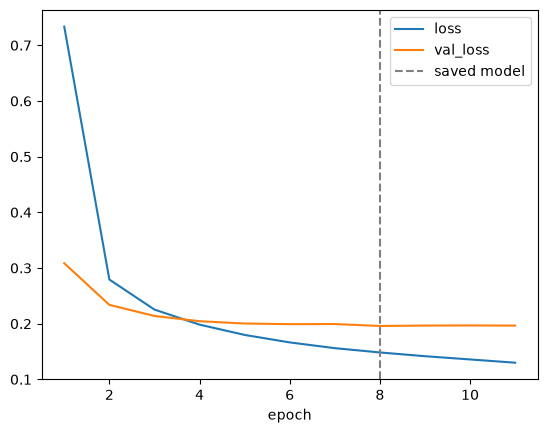

Model in memory:
Test: loss 0.187, accuracy 0.952
Saved model:
Test: loss 0.186, accuracy 0.952


In [13]:
# Reset the seed before drawing the weights: earlier cells no longer matter
keras.utils.set_random_seed(0)
model = build_deep_model()
model.compile(
  optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
callbacks = [
  # Stop after 3 epochs without a decrease of val_loss: the model in memory keeps
  # the weights of the last epoch
  keras.callbacks.EarlyStopping(monitor="val_loss", patience=3),
  # Save the model at each new minimum of val_loss
  keras.callbacks.ModelCheckpoint(
    "best.keras", monitor="val_loss", save_best_only=True
  ),
]
history = model.fit(
  X_train,
  y_train,
  batch_size=128,
  epochs=50,
  validation_split=0.2,
  callbacks=callbacks,
)
nb_epochs = len(history.history["loss"])
# The minimum of val_loss: the epoch ModelCheckpoint saved last
saved_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Epochs run: {nb_epochs}, saved epoch: {saved_epoch}")

epochs = range(1, nb_epochs + 1)
plt.plot(epochs, history.history["loss"], label="loss")
plt.plot(epochs, history.history["val_loss"], label="val_loss")
plt.axvline(saved_epoch, color="gray", linestyle="--", label="saved model")
plt.xlabel("epoch")
plt.legend()
plt.show()

print("Model in memory:")
evaluate(model)
print("Saved model:")
saved_model = keras.models.load_model("best.keras")
evaluate(saved_model)

The training stops at epoch 11, 3 epochs after the minimum of `val_loss` (epoch 8), the one in `best.keras`. The model in memory keeps the weights of the last epoch, the reloaded model those of the minimum: here, their test numbers are almost the same (95.2% both, a loss of 0.187 against 0.186), as `val_loss` barely rises in 3 epochs, but nothing guarantees they will be.

`EarlyStopping` decides when to stop, `ModelCheckpoint` keeps the best model seen on disk; `restore_best_weights=True` would also put the weights of epoch 8 back into memory. On the plot, `loss` still decreases when `val_loss` no longer does: the beginning of overfitting.

## Hyperparameter search

How many neurons in the hidden layer, which learning rate? KerasTuner tries combinations of hyperparameters and keeps the best one, scored on the validation set.

The function `build_model(hp)` returns a perceptron with one ReLU hidden layer, compiled with Adam, the `sparse_categorical_crossentropy` loss and the accuracy. It reads its hyperparameters from `hp`:

- `units`, the number of hidden neurons: from 32 to 512, in steps of 32;
- `learning_rate`, Adam's learning rate: from $10^{-4}$ to $10^{-2}$, on a logarithmic scale.

The search goes through `keras_tuner.BayesianOptimization`: objective `val_accuracy`, 5 trials, each trained 3 times for a less noisy average, 10 epochs per training, batches of 1,500 examples and 20% validation. Finally, we compare the best model with `deep_model`. This is the longest part: a few minutes on CPU.

In [14]:
def build_model(hp: keras_tuner.HyperParameters) -> keras.Model:
  # Each call to hp reads the value the tuner picked for the current trial
  units = hp.Int("units", min_value=32, max_value=512, step=32)
  learning_rate = hp.Float(
    "learning_rate", min_value=1e-4, max_value=1e-2, sampling="log"
  )
  model = keras.Sequential(
    [
      keras.Input(shape=(input_dim,)),
      layers.Dense(units, activation="relu"),
      layers.Dense(nb_classes, activation="softmax"),
    ]
  )
  model.compile(
    optimizer=keras.optimizers.Adam(learning_rate),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
  )
  return model


tuner = keras_tuner.BayesianOptimization(
  build_model,
  objective="val_accuracy",
  max_trials=5,
  executions_per_trial=3,
  seed=0,
  directory="tuner",
  project_name="mnist",
  overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 2
units (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


In [15]:
tuner.search(X_train, y_train, epochs=10, batch_size=1500, validation_split=0.2)

Trial 5 Complete [00h 01m 24s]
val_accuracy: 0.9753333330154419

Best val_accuracy So Far: 0.975777784983317
Total elapsed time: 00h 07m 38s


In [16]:
tuner.results_summary()
best_model = tuner.get_best_models()[0]
best_model.summary()
evaluate(best_model)

Results summary
Results in tuner/mnist
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 2 summary
Hyperparameters:
units: 384
learning_rate: 0.009275112873609005
Score: 0.975777784983317

Trial 4 summary
Hyperparameters:
units: 512
learning_rate: 0.005008298972531056
Score: 0.9753333330154419

Trial 1 summary
Hyperparameters:
units: 448
learning_rate: 0.0011347233933337727
Score: 0.96875

Trial 0 summary
Hyperparameters:
units: 192
learning_rate: 0.0009265280882236007
Score: 0.9589166641235352

Trial 3 summary
Hyperparameters:
units: 448
learning_rate: 0.0004140284427504012
Score: 0.9551111062367758


.../site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 384)            │       301,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         3,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,290 (1.16 MB)

 Trainable params: 305,290 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

Test: loss 0.074, accuracy 0.981


The learning rate matters more than the number of neurons: the trials below $1.2 \times 10^{-3}$ stay between 95.5% and 96.9% in validation, those above $5 \times 10^{-3}$ exceed 97.5%. The best trial (384 neurons, a learning rate of $9.3 \times 10^{-3}$) reaches 97.6% in validation and 98.1% on the test set, better than `deep_model` (95.0%), with 305,290 parameters instead of 17,170. With batches of 1,500 examples, 10 epochs only make 320 weight updates, against 3,750 for `deep_model`: a small learning rate doesn't have time to converge, whatever the size of the model. The trials drawn change from one run to the next; when they only have small learning rates, the best model does worse than `deep_model`.

When it runs, `get_best_models` warns that it doesn't reload the optimizer's state (`Skipping variable loading for optimizer`): the model's weights are there, and they are enough to evaluate it.